In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
df = pd.read_csv("/content/IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
df.shape

(50000, 2)

In [ ]:
df.columns.tolist()

['review', 'sentiment']

In [ ]:
df.isnull().sum(

)

,0
review,0
sentiment,0


In [ ]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


In [ ]:
df.duplicated().sum()

np.int64(418)

In [ ]:
df =df.drop_duplicates().reset_index(drop=True)
df.shape

(49582, 2)

In [ ]:
df["label"] = df['sentiment'].map({
    "positive": 1,
    "negative": 0
})
df.head()

,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
df["clean_review"] = df['review'].apply(clean_text)
df.head()

,review,sentiment,label,clean_review
0,One of the other reviewers has mentioned that ...,positive,1,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,1,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,positive,1,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,0,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1,petter matteis love in the time of money is a ...


In [ ]:
print("Original:")
print(df["review"].iloc[0])

print("\nCleaned:")
print(df["clean_review"].iloc[0])

Original:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due 

In [ ]:
X = df['clean_review'].values
y = df['label'].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, stratify=y, random_state=42
)


In [ ]:
len(X_train), len(X_test)

(39665, 9917)

In [ ]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

MAX_VOCAB_SIZE = 10000

def build_vocab(texts, max_vocab_size=10000):

    word_counts = {}

    for text in texts:
        for word in text.split():
            word_counts[word] = word_counts.get(word, 0) + 1

    sorted_words = sorted(
        word_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )

    vocab = {
        PAD_TOKEN: 0,
        UNK_TOKEN: 1
    }

    for word, count in sorted_words[:max_vocab_size - 2]:
        vocab[word] = len(vocab)

    return vocab

In [ ]:
vocab = build_vocab(
    X_train,
    MAX_VOCAB_SIZE
)

print("Vocabulary size:", len(vocab))

Vocabulary size: 10000


In [ ]:
print(list(vocab.items())[:20])

[('<PAD>', 0), ('<UNK>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10), ('this', 11), ('that', 12), ('was', 13), ('as', 14), ('for', 15), ('with', 16), ('movie', 17), ('but', 18), ('film', 19)]


In [ ]:
def text_to_sequence(text, vocab):

    tokens = text.split()

    sequence = [
        vocab.get(word, vocab[UNK_TOKEN])
        for word in tokens
    ]

    return sequence

In [ ]:
sample_text = X_train[0]

print("Text:")
print(sample_text)

print("\nSequence:")
print(text_to_sequence(sample_text, vocab)[:30])

Text:
i am one of jehovahs witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced by transfused blood i have also heard several jehovahs witnesses being told that they will die if they refuse blood and after years in the field i have never actually seen it happen leaving the question is it really unreasonable to refuse blood transfusions or is the community at large benefiting from the battle on this issue the issue for jehovahs witnesses is a moral one you must abstain from blood is not an ambiguous statement thank you for this movie and allowing comments on it

Sequence:
[10, 229, 28, 5, 1, 4905, 3, 10, 81, 161, 8, 33, 1, 446, 2721, 7710, 129, 2, 151, 10, 25, 105, 83, 763, 35, 1, 3720, 6, 545, 1]


In [ ]:
MAX_LENGTH = 200

In [ ]:
def pad_sequence(sequence, max_length=200):

    if len(sequence) > max_length:
        sequence = sequence[:max_length]

    else:
        sequence = sequence + [0] * (max_length - len(sequence))

    return sequence

In [ ]:
sample_sequence = text_to_sequence(
    X_train[0],
    vocab
)

sample_padded = pad_sequence(
    sample_sequence,
    MAX_LENGTH
)

print("Original length:", len(sample_sequence))
print("Padded length:", len(sample_padded))
print(sample_padded[:30])

Original length: 135
Padded length: 200
[10, 229, 28, 5, 1, 4905, 3, 10, 81, 161, 8, 33, 1, 446, 2721, 7710, 129, 2, 151, 10, 25, 105, 83, 763, 35, 1, 3720, 6, 545, 1]


In [ ]:
class IMDBDataset(Dataset):

    def __init__(self, texts, labels, vocab, max_length):

        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts[index]
        label = self.labels[index]

        sequence = text_to_sequence(
            text,
            self.vocab
        )

        sequence = pad_sequence(
            sequence,
            self.max_length
        )

        return (
            torch.tensor(sequence, dtype=torch.long),
            torch.tensor(label, dtype=torch.float)
        )

In [ ]:
train_dataset = IMDBDataset(
    X_train,
    y_train,
    vocab,
    MAX_LENGTH
)

test_dataset = IMDBDataset(
    X_test,
    y_test,
    vocab,
    MAX_LENGTH
)

In [ ]:
sample_x, sample_y = train_dataset[0]

print("X shape:", sample_x.shape)
print("Y:", sample_y)

print("\nX:")
print(sample_x[:30])

X shape: torch.Size([200])
Y: tensor(1.)

X:
tensor([  10,  229,   28,    5,    1, 4905,    3,   10,   81,  161,    8,   33,
           1,  446, 2721, 7710,  129,    2,  151,   10,   25,  105,   83,  763,
          35,    1, 3720,    6,  545,    1])


In [ ]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
X_batch, y_batch = next(iter(train_loader))

print("X batch shape:", X_batch.shape)
print("Y batch shape:", y_batch.shape)

X batch shape: torch.Size([128, 200])
Y batch shape: torch.Size([128])


In [ ]:
class SentimentRNN(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x):

        # Word IDs → vectors
        embedded = self.embedding(x)

        # RNN
        output, hidden = self.rnn(embedded)

        # Last hidden state
        last_hidden = hidden[-1]

        # Classification
        output = self.fc(last_hidden)

        return output.squeeze(1)

In [ ]:
model = SentimentRNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128
)

model = model.to(device)

print(model)

SentimentRNN(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predicted_labels = (
            torch.sigmoid(predictions) >= 0.5
        ).float()

        correct += (
            predicted_labels == y_batch
        ).sum().item()

        total += y_batch.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [ ]:
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_loss += loss.item()

            probabilities = torch.sigmoid(
                predictions
            )

            predicted_labels = (
                probabilities >= 0.5
            ).float()

            correct += (
                predicted_labels == y_batch
            ).sum().item()

            total += y_batch.size(0)

            all_predictions.extend(
                predicted_labels.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return (
        avg_loss,
        accuracy,
        all_labels,
        all_predictions
    )

In [ ]:
EPOCHS = 5

train_losses = []
train_accuracies = []

test_losses = []
test_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6964 | Train Acc: 0.5049 | Test Loss: 0.6932 | Test Acc: 0.5072
Epoch 2/5 | Train Loss: 0.6888 | Train Acc: 0.5259 | Test Loss: 0.6939 | Test Acc: 0.5073
Epoch 3/5 | Train Loss: 0.6815 | Train Acc: 0.5424 | Test Loss: 0.6925 | Test Acc: 0.5121
Epoch 4/5 | Train Loss: 0.6762 | Train Acc: 0.5509 | Test Loss: 0.7002 | Test Acc: 0.5107
Epoch 5/5 | Train Loss: 0.6723 | Train Acc: 0.5718 | Test Loss: 0.6878 | Test Acc: 0.5835


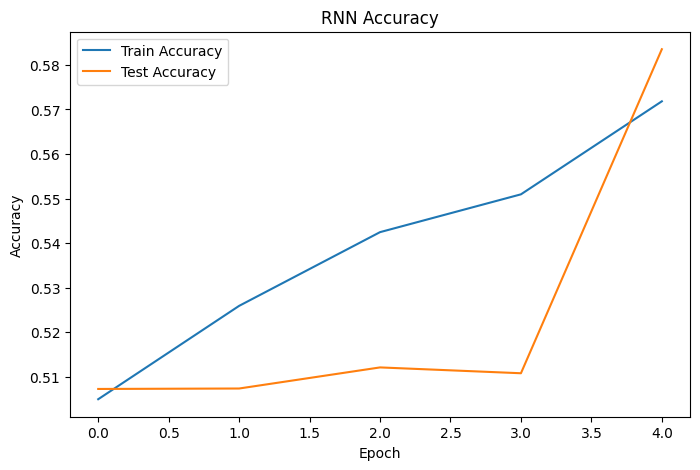

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    test_accuracies,
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Accuracy")

plt.legend()
plt.show()

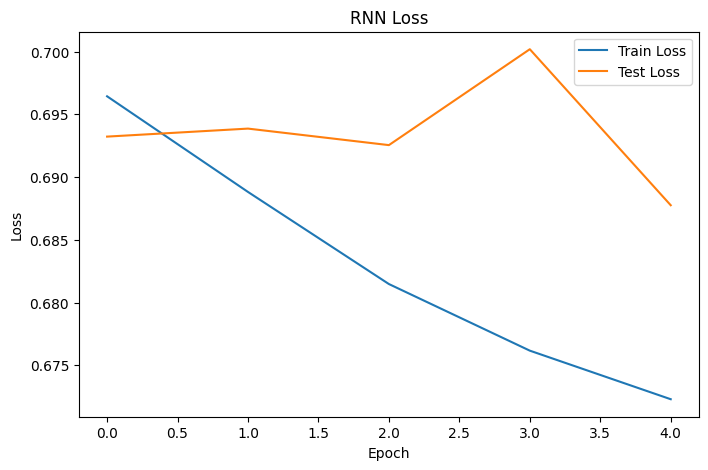

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    test_losses,
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Loss")

plt.legend()
plt.show()

In [ ]:
test_loss, test_acc, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("Test Accuracy:", test_acc)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

Test Accuracy: 0.5835434103055359
              precision    recall  f1-score   support

    Negative       0.60      0.50      0.55      4940
    Positive       0.57      0.66      0.61      4977

    accuracy                           0.58      9917
   macro avg       0.59      0.58      0.58      9917
weighted avg       0.59      0.58      0.58      9917

